/home/pyc/miniconda3/envs/omicverse/lib/python3.10/site-packages/torch/cuda/__init__.py:63: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


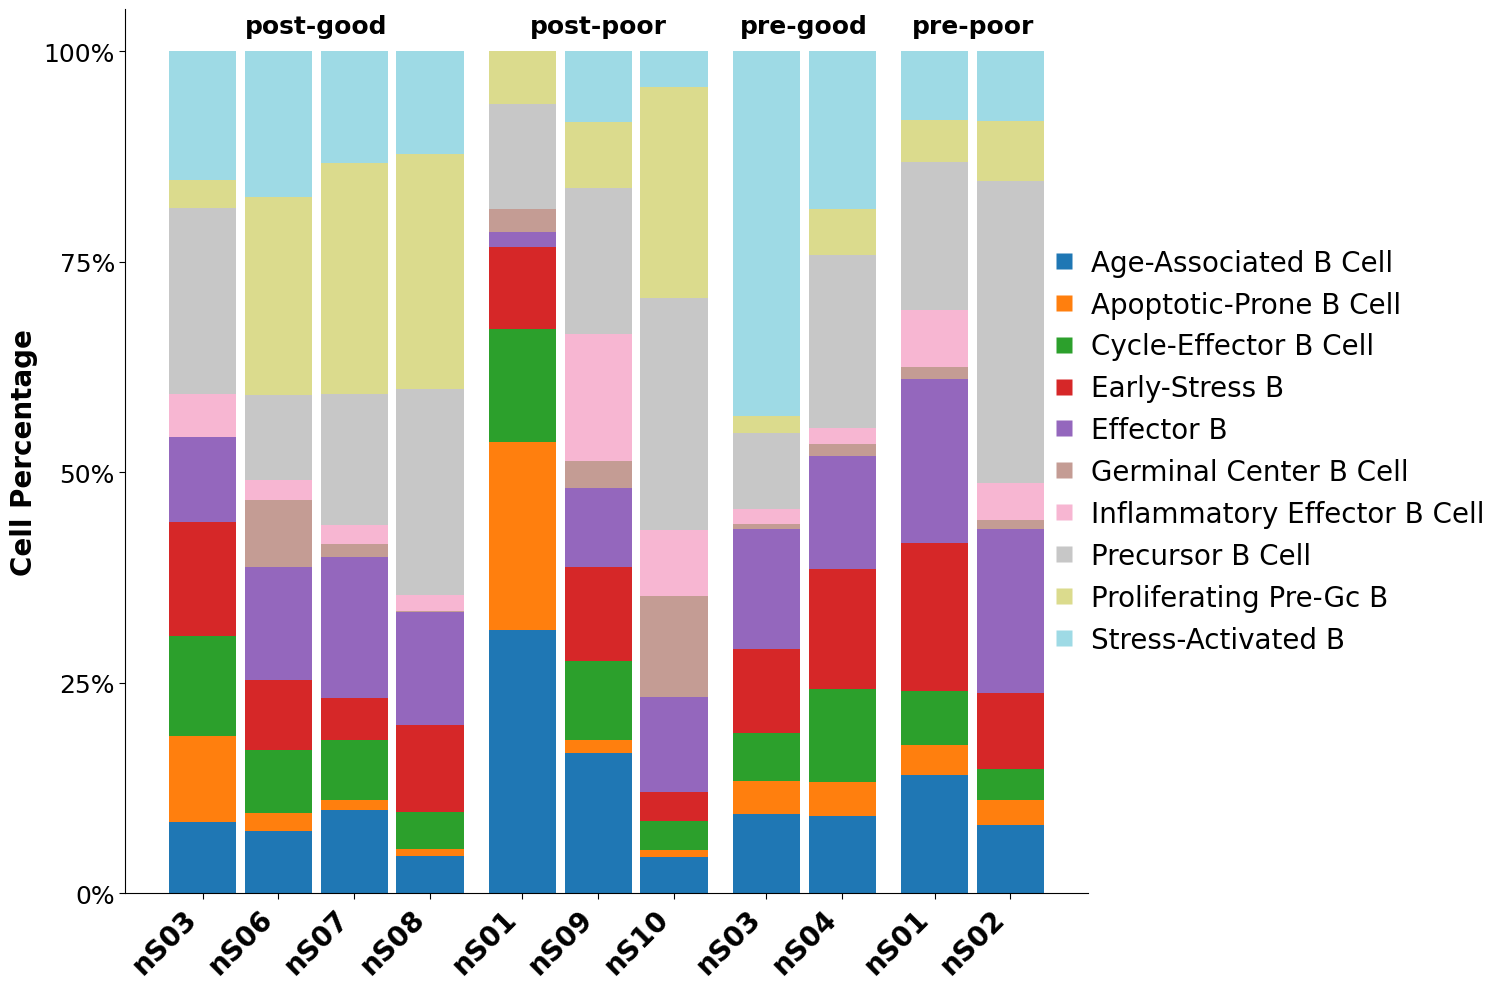

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import matplotlib.patches as mpatches
import scanpy as sc

adata = sc.read("./h5ad/adata_B.h5ad")

# Map each batch to a high-level group
batch2group = {
    "H-nS01":"post-poor",
    "Q-nS01":"pre-poor",
    "Q-nS02":"pre-poor",
    "H-nS08":"post-good",
    "Q-nS03":"pre-good",
    "Q-nS04":"pre-good",
    "H-nS03":"post-good",
    "H-nS06":"post-good",
    "H-nS07":"post-good",
    "H-nS09":"post-poor",
    "H-nS10":"post-poor"
}

# Extract anno and group labels from batch
adata.obs["anno"] = [b.split("-")[1] for b in adata.obs["batch"]]
adata.obs["group"] = [batch2group[b] for b in adata.obs["batch"]]


# Keep only annotation columns needed for plotting
df = adata.obs[['anno', 'group', 'celltype']].copy()


# Build a sorted sample-level table
sample_info = df[['anno', 'group']].drop_duplicates().reset_index(drop=True)
sample_info['group'] = pd.Categorical(sample_info['group'])
sample_info = sample_info.sort_values(['group', 'anno']).reset_index(drop=True)


# Create a unique sample identifier
df['sample_id'] = df['group'].astype(str) + '_' + df['anno'].astype(str)


# Count cells per sample and cell type
counts = df.groupby(['sample_id', 'celltype'], observed=False).size().unstack(fill_value=0)


# Convert counts to percentages
percent = counts.div(counts.sum(axis=1), axis=0)


# Reorder samples according to the sorted sample table
sample_info['sample_id'] = sample_info['group'].astype(str) + '_' + sample_info['anno'].astype(str)
percent = percent.reindex(sample_info['sample_id'])


# Use anno as the final x-axis labels
percent.index = sample_info['anno'].values  


final_celltypes = percent.columns.tolist()


percent.columns = final_celltypes


# Assign colors to cell types
celltypes = percent.columns.tolist() 
n_ct = len(celltypes)
colors = plt.cm.tab20(np.linspace(0, 1, n_ct)) if n_ct <= 20 else plt.cm.Set3(np.linspace(0, 1, n_ct))
color_dict = dict(zip(celltypes, colors))


fig, ax = plt.subplots(figsize=(max(15, len(percent) * 0.7), 10))


# Detect group boundaries for later annotation
group_bounds = []
current_group = None
start_idx = 0
for i, g in enumerate(sample_info['group']):
    if g != current_group:
        if current_group is not None:
            group_bounds.append((current_group, start_idx, i - 1))
        current_group = g
        start_idx = i
group_bounds.append((current_group, start_idx, len(sample_info) - 1))


# Define bar width and spacing
bar_width = 0.8         
gap_within_group = 0.1  
gap_between_groups = 0.2  

x_positions = []
current_x = 0

# Compute x positions so that samples within the same group are closer
for group, start, end in group_bounds:
    n_samples = end - start + 1
    for j in range(n_samples):
        x_positions.append(current_x + j * (bar_width + gap_within_group))
    current_x += n_samples * (bar_width + gap_within_group) + gap_between_groups


# Plot stacked bar chart by cell type
bottom = np.zeros(len(x_positions))
for ct in celltypes: 
    values = percent[ct].values
    ax.bar(x_positions, values, bottom=bottom, width=bar_width, color=color_dict[ct], edgecolor='none')
    bottom += values

# Add group labels above each group
rect_y_bottom = 1.02
rect_height = 0.06

for group, start, end in group_bounds:
    start_x = x_positions[start]
    end_x = x_positions[end]
    left = start_x - bar_width / 2
    right = end_x + bar_width / 2
    width = right - left
    
    rect = mpatches.Rectangle(
        (left, rect_y_bottom),
        width,
        rect_height,
        facecolor='white',
        edgecolor='black',
        linewidth=1
    )
    
    center_x = (start_x + end_x) / 2
    text_y = rect_y_bottom + rect_height / 2
    ax.text(center_x, text_y-0.02, str(group),
            ha='center', va='center',
            fontweight='bold', fontsize=18)


# Configure axes
ax.set_ylim(0, 1.05)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_yticklabels(['0%', '25%', '50%', '75%', '100%'],fontsize=18)
ax.set_xticks(x_positions)
ax.set_xticklabels(percent.index, rotation=45, ha='right', fontsize=20,fontweight="bold")


# Build legend
legend_elements = [
    plt.Line2D([0], [0], marker='s', color='w', label=ct,
               markerfacecolor=color_dict[ct], markersize=12, markeredgecolor='none')
    for ct in celltypes # Legend uses the processed cell type names
]
leg = ax.legend(handles=legend_elements, 
                loc='center left',      
                bbox_to_anchor=(0.92, 0.5),
                frameon=True,           
                facecolor='white',      
                edgecolor='none',       
                fontsize=20, 
                title='',
                handletextpad=0)

leg.set_zorder(0)


# Clean up spines and ticks
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(0.8)
ax.spines['bottom'].set_linewidth(0.8)
ax.tick_params(axis='both', which='major', length=4, width=0.8)
ax.set_ylabel('Cell Percentage', fontsize=20,fontweight="bold")

plt.tight_layout()
plt.show()

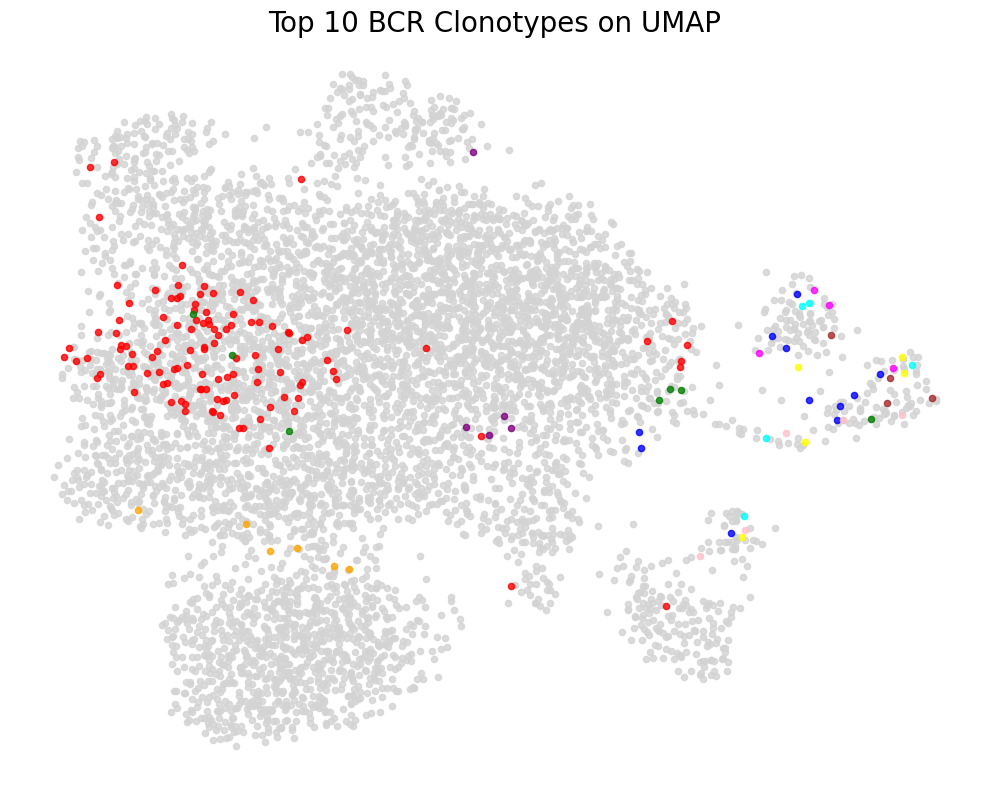

In [15]:
import matplotlib.pyplot as plt

# 1. Identify the largest clonotypes (top 11; the most abundant one, usually None, is assigned lightgrey)
top_clones = adata.obs['bcr_clonotype_id'].value_counts().head(11).index
colors = ['lightgrey', 'red', 'blue', 'green', 'orange', 'purple',
          'yellow', 'pink', 'cyan', 'magenta', 'brown', 'lime']  # Colors for the top clonotypes

# 2. Create the figure using the object-oriented interface
fig, ax = plt.subplots(figsize=(10, 8))

# Plot background: all other cells in lightgray
other_mask = ~adata.obs['bcr_clonotype_id'].isin(top_clones)
ax.scatter(
    adata[other_mask].obsm['X_umap'][:, 0],
    adata[other_mask].obsm['X_umap'][:, 1],
    c='lightgray', s=20, alpha=0.8, label='Other cells'
)

# 3. Plot each large clonotype separately
for i, clone_id in enumerate(top_clones):
    clone_mask = adata.obs['bcr_clonotype_id'] == clone_id
    ax.scatter(
        adata[clone_mask].obsm['X_umap'][:, 0],
        adata[clone_mask].obsm['X_umap'][:, 1],
        c=colors[i], s=20, alpha=0.8, label=f'{clone_id}'
    )

# Key: remove all axes and border elements
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_title('')

# Hide the four spines
for spine in ax.spines.values():
    spine.set_visible(False)

plt.title('Top 10 BCR Clonotypes on UMAP', fontsize=20)

# Display the plot
plt.tight_layout()
plt.show()

Normalized count data: X, spliced, unspliced.
computing neighbors


/tmp/ipykernel_1236872/3905028934.py:8: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scv.pp.moments(adata, n_pcs=30, n_neighbors=30)
/home/pyc2/miniconda3/envs/scvelo_env/lib/python3.10/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(


    finished (0:00:11) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:04) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:20) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/128 cores)
or disable the progress bar using `show_progress_bar=False`.
    finished (0:00:10) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:01) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


/home/pyc2/miniconda3/envs/scvelo_env/lib/python3.10/site-packages/scvelo/plotting/utils.py:68: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  return isinstance(c, str) and c in data.obs.keys() and cat(data.obs[c])
/home/pyc2/miniconda3/envs/scvelo_env/lib/python3.10/site-packages/scvelo/plotting/utils.py:68: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  return isinstance(c, str) and c in data.obs.keys() and cat(data.obs[c])


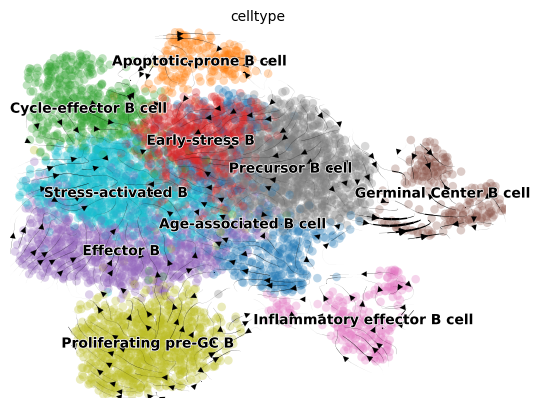

In [1]:
import scvelo as scv
import scanpy as sc
import numpy as np

adata = sc.read('./h5ad/adata_B_velocity.h5ad')

# Calculate moments (in preparation for velocity)
scv.pp.moments(adata, n_pcs=30, n_neighbors=30)

# Calculate velocity
scv.tl.velocity(adata, mode='deterministic')

# Velocity_graph
scv.tl.velocity_graph(adata)

# Visual check
scv.pl.velocity_embedding_stream(adata, basis='umap', color='celltype')

In [20]:
import scanpy as sc
import omicverse as ov
from omicverse.external import VIA

import matplotlib.pyplot as plt
ov.plot_set()

🔬 Starting plot initialization...
🧬 Detecting CUDA devices…
✅ [GPU 0] NVIDIA GeForce RTX 4090
    • Total memory: 23.5 GB
    • Compute capability: 8.9
✅ [GPU 1] NVIDIA GeForce RTX 4090
    • Total memory: 23.5 GB
    • Compute capability: 8.9

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: 1.7.7   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.



In [21]:
ncomps=30
knn=15
v0_random_seed=4
root_user = ["Early-stress B"]
memory = 10
dataset = ''
use_rep = 'X_pca_harmony'
clusters = 'celltype'
basis='X_umap'

v0 = VIA.core.VIA(data=adata.obsm[use_rep][:, 0:ncomps], 
             true_label=adata.obs[clusters], 
             edgepruning_clustering_resolution=0.15, cluster_graph_pruning=0.15,
             knn=knn,  root_user=root_user, resolution_parameter=1.5,
             dataset=dataset, random_seed=v0_random_seed, memory=memory,velocity_matrix=adata.layers['velocity'],   
             velo_weight=0.5)

v0.run_VIA()

2026-10-25 13:12:06.287312	Running VIA over input data of 6332 (samples) x 30 (features)
2026-10-25 13:12:06.287468	Knngraph has 15 neighbors
2026-10-25 13:12:10.305873	Finished global pruning of 15-knn graph used for clustering at level of 0.15. Kept 44.9 % of edges. 
2026-10-25 13:12:10.328216	Number of connected components used for clustergraph  is 1
2026-10-25 13:12:10.435337	Commencing community detection
2026-10-25 13:12:10.865959	Finished community detection. Found 142 clusters.
2026-10-25 13:12:10.867903	Merging 112 very small clusters (<10)
2026-10-25 13:12:10.869986	Finished detecting communities. Found 30 communities
2026-10-25 13:12:10.870332	Making cluster graph. Global cluster graph pruning level: 0.15
2026-10-25 13:12:10.881029	Graph has 1 connected components before pruning
2026-10-25 13:12:10.882995	Graph has 1 connected components after pruning
2026-10-25 13:12:10.883139	Graph has 1 connected components after reconnecting
2026-10-25 13:12:10.883647	0.0% links trimmed 

/home/pyc/miniconda3/envs/omicverse/lib/python3.10/site-packages/torch/cuda/__init__.py:63: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]
/home/pyc/miniconda3/envs/omicverse/lib/python3.10/site-packages/torch/cuda/__init__.py:63: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


2026-10-25 13:12:29.177143	Ended all multiprocesses, will retrieve and reshape
2026-10-25 13:12:29.232415	start computing walks with rw2 method


  0%|                                                                                          | 0/1300 [00:00…

memory for rw2 hittings times  2. Using rw2 based pt
2026-10-25 13:12:40.974912	Identifying terminal clusters corresponding to unique lineages...
2026-10-25 13:12:40.974934	Closeness:[0, 2, 3, 4, 6, 9, 11, 13, 14, 16, 17, 20, 23, 28]
2026-10-25 13:12:40.974943	Betweenness:[0, 2, 4, 6, 8, 9, 10, 12, 13, 15, 16, 17, 19, 20, 22, 23, 24, 26, 28]
2026-10-25 13:12:40.974950	Out Degree:[0, 2, 3, 4, 6, 9, 11, 13, 16, 17, 18, 19, 20, 21, 23, 24, 27, 28, 29]
2026-10-25 13:12:40.975123	Cluster 2 had 3 or more neighboring terminal states [3, 4, 11] and so we removed cluster 3
2026-10-25 13:12:40.975164	Cluster 4 had 3 or more neighboring terminal states [2, 6, 11] and so we removed cluster 6
2026-10-25 13:12:40.975220	We removed cluster 19 from the shortlist of terminal states
2026-10-25 13:12:40.975359	Terminal clusters corresponding to unique lineages in this component are [0, 2, 4, 9, 11, 13, 16, 17, 20, 23, 24, 28] 
2026-10-25 13:12:40.975376	Calculating lineage probability at memory 10


  0%|                                                                                          | 0/1000 [00:00…

2026-10-25 13:12:45.954994	Cluster or terminal cell fate 0 is reached 149.0 times
2026-10-25 13:12:45.992016	Cluster or terminal cell fate 2 is reached 571.0 times
2026-10-25 13:12:46.037574	Cluster or terminal cell fate 4 is reached 572.0 times
2026-10-25 13:12:46.076946	Cluster or terminal cell fate 9 is reached 149.0 times
2026-10-25 13:12:46.106017	Cluster or terminal cell fate 11 is reached 571.0 times
2026-10-25 13:12:46.146288	Cluster or terminal cell fate 13 is reached 2.0 times
2026-10-25 13:12:46.188229	Cluster or terminal cell fate 16 is reached 2.0 times
2026-10-25 13:12:46.225061	Cluster or terminal cell fate 17 is reached 162.0 times
2026-10-25 13:12:46.264563	Cluster or terminal cell fate 20 is reached 77.0 times
2026-10-25 13:12:46.299928	Cluster or terminal cell fate 23 is reached 281.0 times
2026-10-25 13:12:46.335205	Cluster or terminal cell fate 24 is reached 281.0 times
2026-10-25 13:12:46.375551	Cluster or terminal cell fate 28 is reached 2.0 times
2026-10-25 13:1

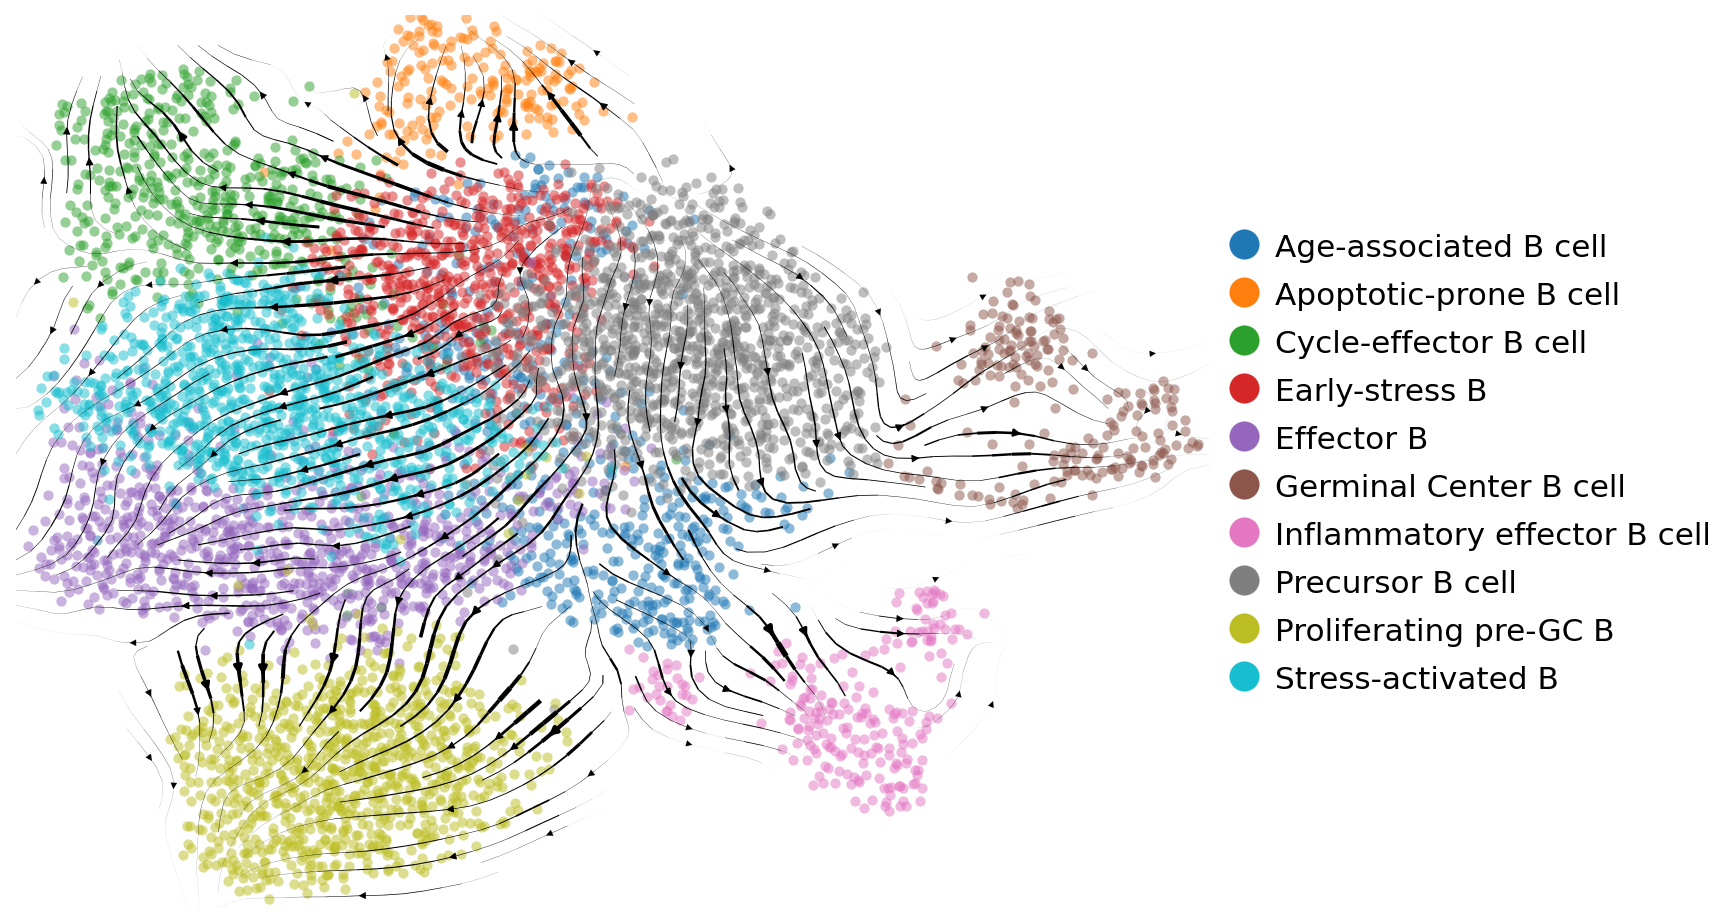

In [26]:
fig, ax = VIA.core.via_streamplot_ov(adata, 'celltype', v0,
                                    embedding=adata.obsm['X_umap'], 
                                    dpi=80,
                                    density_grid=0.75, 
                                    scatter_size=20, 
                                    scatter_alpha=0.5,
                                    linewidth=1.5,
                                    cmap='tab20',
                                    show_text_labels=False,
                                    title="",
                                    bg_color='white')

fig.set_size_inches(11, 6)

# Legend
legend = ax.legend(bbox_to_anchor=(1.0, 0.5), 
                  loc='center left',
                  fontsize=14,
                  markerscale=3, 
                  handlelength=1.2,
                  handleheight=1.2)

plt.tight_layout()
fig.patch.set_facecolor('white')
ax.set_facecolor('white')
for handle in legend.legend_handles:
    handle.set_alpha(1.0)
plt.show()